In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import os
from datetime import datetime
import pandas as pd
import plotly.express as px


mpl.rcParams['figure.figsize'] = (10, 8)
mpl.rcParams['axes.grid'] = False

In [2]:
def parse(x):
  return datetime.strptime(x,'%m/%d/%Y')

### Data Importation

In [33]:
df = pd.read_csv('https://raw.githubusercontent.com/srivatsan88/YouTubeLI/master/dataset/amazon_revenue_profit.csv',parse_dates=['Quarter'],date_parser= parse)
df.head()

<ipython-input-33-02be98f1e742>:1: FutureWarning:

The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.



,Quarter,Revenue,Net Income
0,2020-03-31,75452,2535
1,2019-12-31,87437,3268
2,2019-09-30,69981,2134
3,2019-06-30,63404,2625
4,2019-03-31,59700,3561


### Data Visualization

In [7]:
fig = px.line(df,x='Quarter',y='Revenue',title = "Amazon Revenue")
fig.update_xaxes(
    rangeslider_visible=True,
    rangeselector = dict(
        buttons = list([
            dict(count = 1, step = "year",label = "1 year",stepmode= "backward"),
            dict(count = 2, step = "year",label="2 years",stepmode = "backward"),
            dict(count = 3, step = "year",label="3 years",stepmode = "backward"),
            dict(step = "all")
        ])))
fig.show()

From the visualization the series is not stationary and is potraying an increase in trend over the years.

### Test for Stationarity

## KPSS Test

In [8]:
from statsmodels.tsa.stattools import kpss
result = kpss(df['Revenue'],'ct')
print(result)

(0.30665545975169417, 0.01, 4, {'10%': 0.119, '5%': 0.146, '2.5%': 0.176, '1%': 0.216})


<ipython-input-8-849b7a25ab36>:2: InterpolationWarning:

The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.




In [9]:
print(f'The test statistic is {result[0]}')
print(f'The p-value is {result[1]}')
print(f'The critical values are {result[3]}')
if result[1] < 0.05:
  print('The series is non-stationary')
else:
  print('The series is stationary')

The test statistic is 0.30665545975169417
The p-value is 0.01
The critical values are {'10%': 0.119, '5%': 0.146, '2.5%': 0.176, '1%': 0.216}
The series is non-stationary


### Time Series Decomposition

The purpose for decomposition as

ime series decomposition is a technique used to break down a time series into its individual components. These components typically include:

Trend: The overall direction of the series (increasing, decreasing, or flat).
Seasonality: Regular patterns that repeat over a fixed period (e.g., daily, weekly, monthly).
Residuals: The remaining variation in the data after accounting for trend and seasonality, which is often considered random or noise.
Why is this useful?

Understanding the data: By isolating the individual components, you can gain insights into the underlying forces driving the time series data, like economic cycles, promotions, or external factors.

Forecasting: Decomposition helps improve forecast accuracy by modeling each component separately and combining them to generate predictions. For example, you can isolate and model seasonality or trend, making your forecast more accurate.

Anomaly Detection: You can identify unusual observations and potentially remove them before applying forecasting models by understanding the typical behavior of each component. Deviations from seasonal or trend patterns can be flagged as potential outliers.

Data Visualization: Decomposed components can be plotted individually to facilitate a deeper comprehension of the time series. This can aid in identifying crucial features of the data.

Data Preprocessing: You might remove or adjust for the effect of seasonality or trend before applying machine learning models since certain algorithms assume stationarity.


Additive model : $ y_{t} = T_{t} +C_{t}+S_{t} + I_{t}$


Multiplicative model = $y_{t} = T_{t} \times C_{t}\times S_{t} \times I_{t} $

Whenever our series is non-stationary we use the Multiplicative model then if our series is stationary we use the additive model

In [34]:
amazon_df = df.copy()
amazon_df.set_index('Quarter',inplace=True)
amazon_df.head()

,Revenue,Net Income
Quarter,,
2020-03-31,75452,2535
2019-12-31,87437,3268
2019-09-30,69981,2134
2019-06-30,63404,2625
2019-03-31,59700,3561


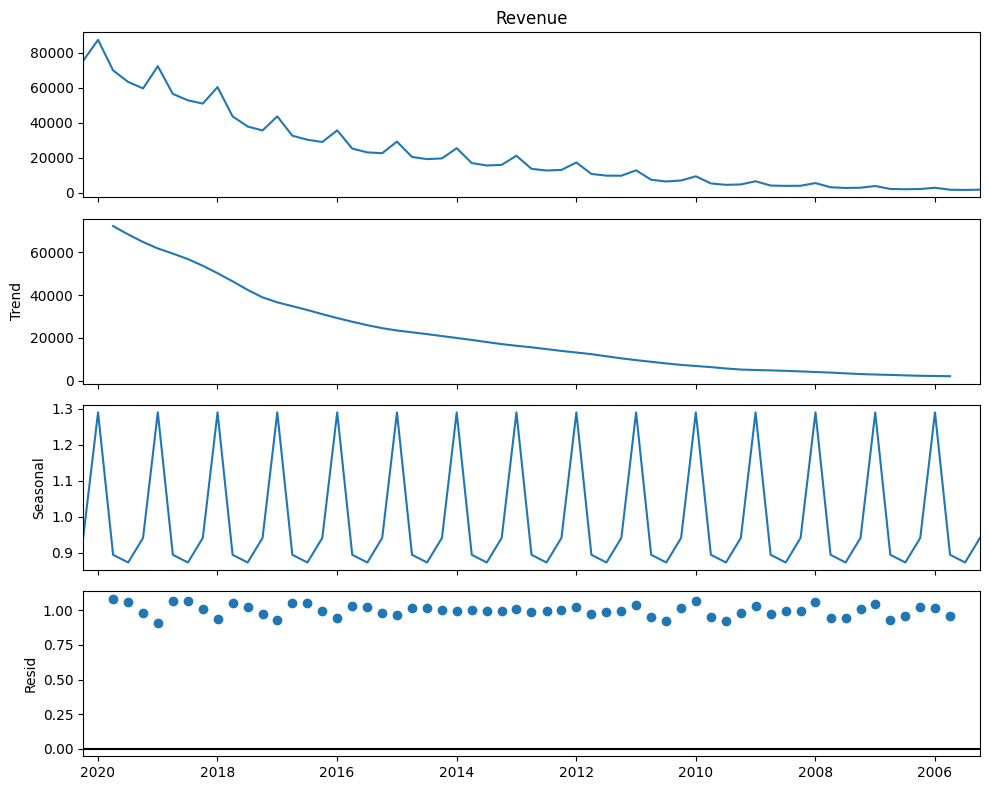

In [41]:
import statsmodels.api as sm
res = sm.tsa.seasonal_decompose(amazon_df['Revenue'],model = 'multiplicative')
res_plot = res.plot()

<Axes: xlabel='Quarter'>

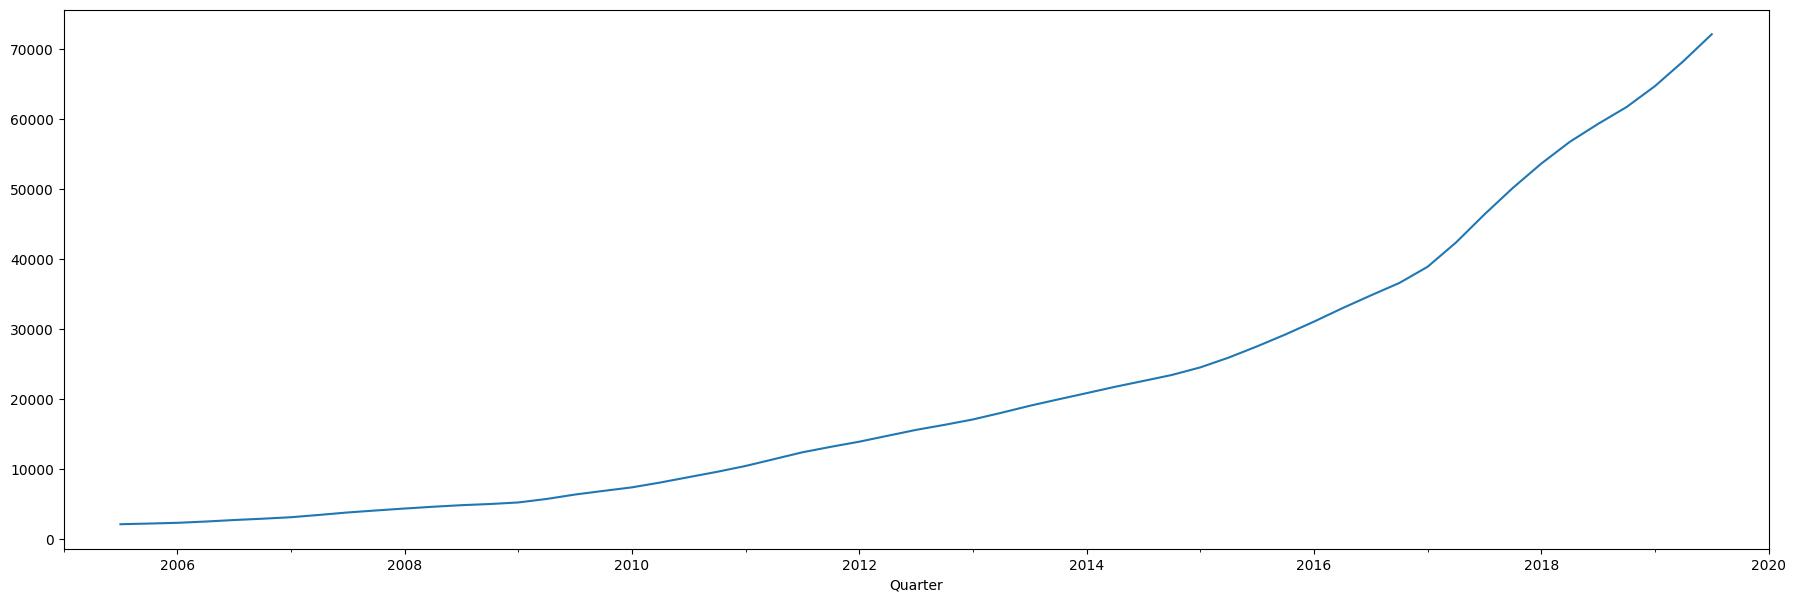

In [37]:
plt.figure(figsize=(22,7))
res.trend.plot()

<Axes: xlabel='Quarter'>

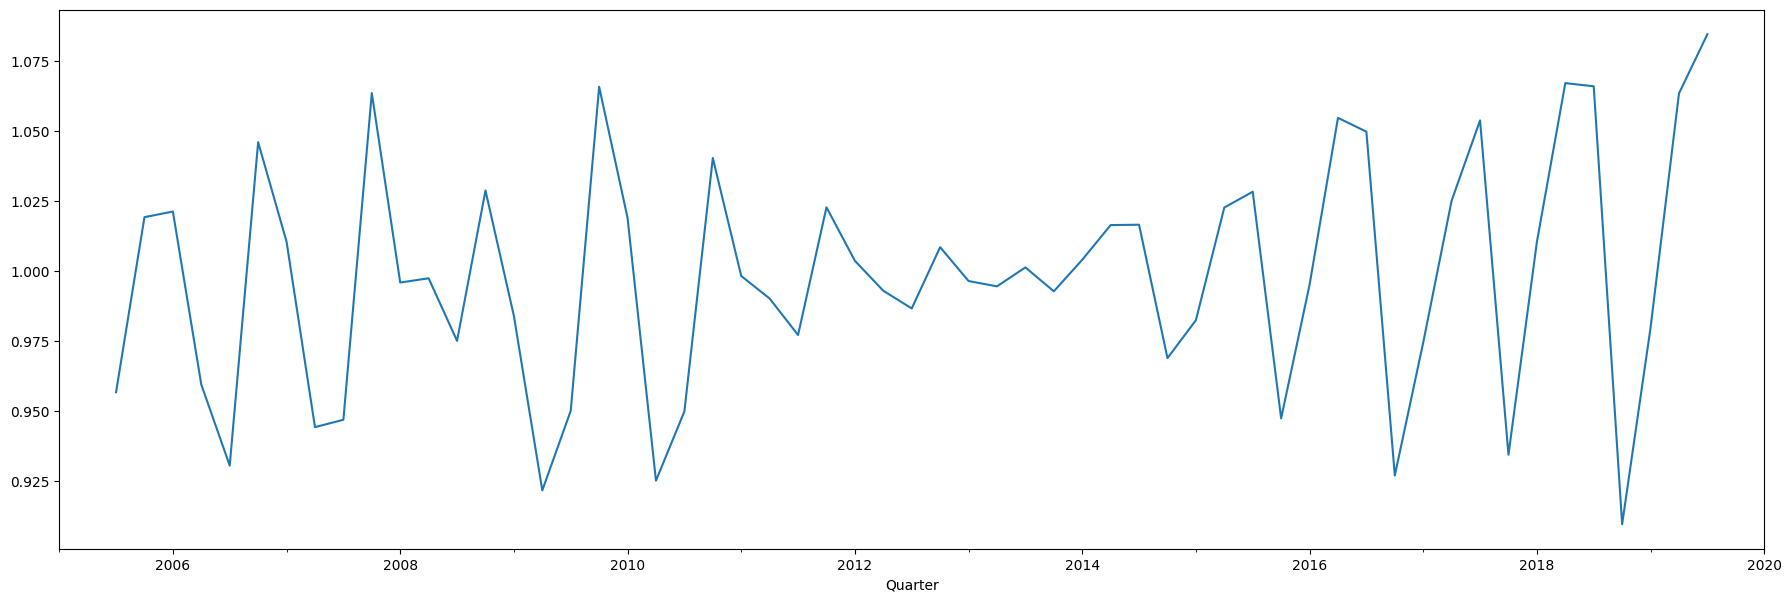

In [38]:
plt.figure(figsize = (22,7))
res.resid.plot()

In [42]:
res.observed[2]

<ipython-input-42-61b2a7bb65f3>:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



69981.0

In [43]:
#using the multiplicative model to check if the result is the observed value
res.trend[2]*res.seasonal[2]*res.resid[2]

<ipython-input-43-210e4034ce84>:2: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



69980.99999999999

<Axes: xlabel='Quarter'>

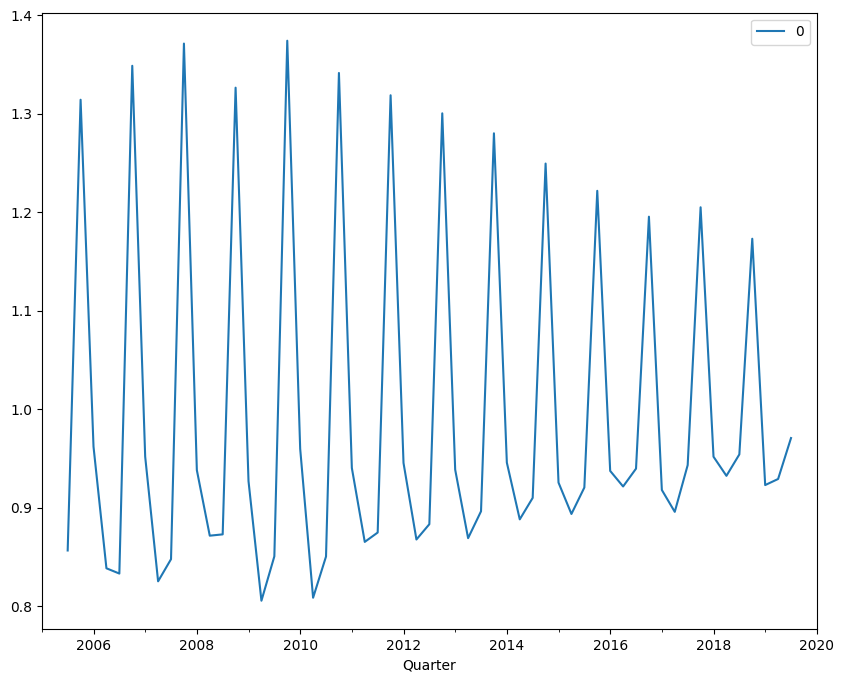

In [44]:
pd.DataFrame(res.observed/res.trend).plot()

This gives us the seasonality graph here